# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/damiannogueira/flyrank-ml-intership/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

### Decision-support queue

The validated model is not strong enough to automate content actions. Under the client-grouped evaluation, Logistic Regression reached 28.0% Precision@50 against a 29.9% positive base rate.

For this playbook, I therefore use a transparent opportunity queue rather than treating the model score as an automatic decision.

A page enters the review queue when:

- it had at least **500 search impressions** during the March 1–21 pre-decision window; and
- its weighted average search position was at least **4 and below 20**.

These conditions identify pages with measured search visibility that are either already on page one or close to it. They do not prove that a page needs a refresh or that an intervention will improve performance.

### Archetype → action mapping

**`PAGE_ONE_VISIBLE`**
- Position: 4 to below 10
- Reason code: `page_one_visible`
- Action: `REVIEW_CLICK_CAPTURE`
- Human interpretation: the page already has strong search visibility, so review its search-result click capture, intent match, title, description, and content promise before considering larger changes.

**`STRIKING_DISTANCE`**
- Position: 10 to below 20
- Reason code: `striking_distance_visible`
- Action: `REVIEW_REFRESH`
- Human interpretation: the page already has measurable demand and is close to page one, so review freshness, topical coverage, internal linking, and whether the content still matches the query intent.

Within both archetypes, higher pre-decision impressions receive higher review priority. This is an opportunity-ranking rule, not a probability of future decline.

The refresh action is deliberately phrased as `REVIEW_REFRESH`: earlier portfolio evidence showed directional relationships between freshness, age, and performance, but observational data does not establish that refreshing a page will cause an improvement.

In [1]:
# Build a transparent human-review queue from pre-decision search data.
# The queue prioritizes opportunity; it does not predict guaranteed outcomes.

%pip -q install duckdb

from google.colab import userdata
import duckdb
import pandas as pd


# Load the warehouse token securely from Colab Secrets.
HF_TOKEN = userdata.get("HF_TOKEN")

con = duckdb.connect()

con.execute(
    f"CREATE OR REPLACE SECRET hf "
    f"(TYPE huggingface, TOKEN '{HF_TOKEN}')"
)


# Use the same March 2026 development partition as earlier assignments.
MARCH_REL = """
read_parquet(
    'hf://datasets/FlyRank/internship-warehouse/fact_content_daily_performance/month=2026-03/*.parquet'
)
"""


# Build one pre-decision row per client/content item using March 1-21 only.
action_frame = con.sql(f"""
    SELECT
        client_hash_id,
        content_hash_id,

        SUM(gsc_impressions) AS impressions_21d,
        SUM(gsc_clicks) AS clicks_21d,

        SUM(gsc_sum_position)
            / NULLIF(SUM(gsc_impressions), 0)
            AS avg_position_21d,

        COUNT(
            DISTINCT CASE
                WHEN gsc_impressions > 0 THEN report_date
            END
        ) AS active_days_21d

    FROM {MARCH_REL}

    WHERE
        gsc_data_available IS TRUE
        AND report_date
            BETWEEN DATE '2026-03-01'
            AND DATE '2026-03-21'

    GROUP BY
        client_hash_id,
        content_hash_id

    HAVING SUM(gsc_impressions) > 0
""").df()


# CTR is a descriptive pre-decision metric, not an action trigger.
action_frame["ctr_21d"] = (
    100.0
    * action_frame["clicks_21d"]
    / action_frame["impressions_21d"]
)


# Keep only pages with meaningful visibility in positions 4-19.99.
action_queue = action_frame[
    (action_frame["impressions_21d"] >= 500)
    & (action_frame["avg_position_21d"] >= 4)
    & (action_frame["avg_position_21d"] < 20)
].copy()


# Map transparent search-position archetypes to review actions.
action_queue["archetype"] = "STRIKING_DISTANCE"
action_queue["reason_code"] = "striking_distance_visible"
action_queue["action_label"] = "REVIEW_REFRESH"

page_one_mask = action_queue["avg_position_21d"] < 10

action_queue.loc[page_one_mask, "archetype"] = "PAGE_ONE_VISIBLE"
action_queue.loc[page_one_mask, "reason_code"] = "page_one_visible"
action_queue.loc[page_one_mask, "action_label"] = "REVIEW_CLICK_CAPTURE"


# Existing search visibility is used only as an opportunity-priority score.
action_queue["priority_score"] = action_queue["impressions_21d"]


# Rank deterministically so a clean rerun produces the same queue.
action_queue = action_queue.sort_values(
    [
        "priority_score",
        "client_hash_id",
        "content_hash_id",
    ],
    ascending=[False, True, True],
    kind="stable",
).reset_index(drop=True)

action_queue.insert(
    0,
    "rank",
    range(1, len(action_queue) + 1),
)


queue_columns = [
    "rank",
    "client_hash_id",
    "content_hash_id",
    "archetype",
    "reason_code",
    "action_label",
    "priority_score",
    "impressions_21d",
    "clicks_21d",
    "ctr_21d",
    "avg_position_21d",
    "active_days_21d",
]

action_queue = action_queue[queue_columns]


print(f"Pages in human-review queue: {len(action_queue):,}")
print()
print("Queue by archetype:")
display(
    action_queue["archetype"]
    .value_counts()
    .rename_axis("archetype")
    .reset_index(name="pages")
)

print()
print("Top 10 review priorities:")
action_queue.head(10)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Pages in human-review queue: 28,474

Queue by archetype:


,archetype,pages
0,PAGE_ONE_VISIBLE,20916
1,STRIKING_DISTANCE,7558



Top 10 review priorities:


,rank,client_hash_id,content_hash_id,archetype,reason_code,action_label,priority_score,impressions_21d,clicks_21d,ctr_21d,avg_position_21d,active_days_21d
0,1,client_23a62021009f63c4,content_e8a52cf3d5988c07,STRIKING_DISTANCE,striking_distance_visible,REVIEW_REFRESH,179025.0,179025.0,472.0,0.263650,15.593699,21
1,2,client_08a6a72ff48e62c0,content_e7b5dd4dff461ad2,PAGE_ONE_VISIBLE,page_one_visible,REVIEW_CLICK_CAPTURE,127816.0,127816.0,1532.0,1.198598,4.322690,21
2,3,client_62f4a7e64f5e0096,content_b99ea6861864dea5,PAGE_ONE_VISIBLE,page_one_visible,REVIEW_CLICK_CAPTURE,125082.0,125082.0,245.0,0.195872,4.448818,21
3,4,client_73cda7b4e4f265ea,content_471d9cabce329a66,PAGE_ONE_VISIBLE,page_one_visible,REVIEW_CLICK_CAPTURE,110663.0,110663.0,275.0,0.248502,4.544301,21
4,5,client_62f4a7e64f5e0096,content_7c6373141eae744a,PAGE_ONE_VISIBLE,page_one_visible,REVIEW_CLICK_CAPTURE,100270.0,100270.0,57.0,0.056847,5.813135,21
5,6,client_20259bd6705d81d4,content_82e35c4845e6c391,STRIKING_DISTANCE,striking_distance_visible,REVIEW_REFRESH,96942.0,96942.0,38.0,0.039199,18.343680,21
6,7,client_23a62021009f63c4,content_5e1c049f62e33b11,STRIKING_DISTANCE,striking_distance_visible,REVIEW_REFRESH,89534.0,89534.0,135.0,0.150781,17.834231,21
7,8,client_62f4a7e64f5e0096,content_f6116743b00afc2d,PAGE_ONE_VISIBLE,page_one_visible,REVIEW_CLICK_CAPTURE,81123.0,81123.0,10.0,0.012327,9.857661,21
8,9,client_73cda7b4e4f265ea,content_f43118e089ecc69a,PAGE_ONE_VISIBLE,page_one_visible,REVIEW_CLICK_CAPTURE,80299.0,80299.0,129.0,0.160650,4.853248,21
9,10,client_73cda7b4e4f265ea,content_95ff62babbfac9c7,PAGE_ONE_VISIBLE,page_one_visible,REVIEW_CLICK_CAPTURE,78330.0,78330.0,155.0,0.197881,4.581667,21


### Queue result

The human-review queue contains **28,474 pages** based only on information available in the March 1–21 pre-decision window.

Of these, **20,916** are classified as `PAGE_ONE_VISIBLE` and receive the `REVIEW_CLICK_CAPTURE` action, while **7,558** are classified as `STRIKING_DISTANCE` and receive the `REVIEW_REFRESH` action.

The highest-ranked pages are not necessarily the pages most likely to decline. They are the pages with the greatest measured pre-decision search visibility among those that meet the review criteria.

This distinction is important: `priority_score` represents review opportunity, not predicted uplift, decline probability, or expected business value.

Unlike the earlier validation frame, this operational queue does not require a page to have observations in the future outcome window. That keeps the playbook usable with information that would actually be available at the decision point.

## 2. Intended use and limits

### Intended use

This playbook is intended for SEO, content, or editorial teams that need a transparent way to prioritize manual review across a large content portfolio.

The ranked queue is designed to answer a limited operational question:

> Which already-visible pages look worth reviewing first, and why?

Each recommendation includes an interpretable reason code and review action so that a human can understand why a page appears in the queue before deciding whether any change is appropriate.

The playbook is decision-support only. It is not an automated publishing, rewriting, deletion, or optimization system.

### Limits

The queue does not estimate causal uplift and should not be interpreted as evidence that a recommended action will improve search performance.

The `priority_score` reflects existing search visibility, not decline probability, expected clicks, revenue, or business value.

The Week-6 validation also limits how strongly the model can be used. Under a client-grouped split, Logistic Regression measured **28.0% Precision@50** against a **29.9%** positive base rate. This does not support using the model as a reliable automatic decision rule for unseen clients.

The current playbook was developed from the March 2026 FlyRank portfolio data and should not be assumed to transfer unchanged to other portfolios, clients, periods, or search environments.

Human context remains necessary because metrics alone do not capture content accuracy, brand priorities, commercial importance, legal constraints, editorial quality, or whether a page is intentionally serving a narrow purpose.

### Cost and value

Queue rank should be considered together with the estimated effort of the proposed review.

A high-visibility page may justify earlier review because more existing search exposure is involved, but the queue does not measure the monetary value of that exposure. A reviewer should compare the likely effort of an intervention with its business importance before acting.

Small, reversible checks such as reviewing search intent, titles, descriptions, or internal links may be lower-cost first steps. Larger rewrites, migrations, deletions, or technical changes require stronger evidence and additional review.

The playbook therefore prioritizes where to investigate first; it does not calculate return on investment or prescribe how much effort a page should receive.

In [2]:
# Document the intended use and boundaries of the playbook.

playbook_scope = pd.DataFrame(
    [
        {
            "area": "Primary use",
            "allowed": True,
            "guidance": "Prioritize pages for human SEO/content review",
        },
        {
            "area": "Action execution",
            "allowed": False,
            "guidance": "Do not automatically rewrite, publish, delete, or redirect content",
        },
        {
            "area": "Model interpretation",
            "allowed": False,
            "guidance": "Do not treat model score as a guaranteed decline probability",
        },
        {
            "area": "Causal claims",
            "allowed": False,
            "guidance": "Do not claim that refresh or click-capture changes will cause improvement",
        },
        {
            "area": "Business value",
            "allowed": False,
            "guidance": "Priority score is visibility, not revenue or expected uplift",
        },
        {
            "area": "Generalization",
            "allowed": False,
            "guidance": "Do not assume the March 2026 rules transfer unchanged to other portfolios",
        },
    ]
)

playbook_scope


,area,allowed,guidance
0,Primary use,True,Prioritize pages for human SEO/content review
1,Action execution,False,"Do not automatically rewrite, publish, delete,..."
2,Model interpretation,False,Do not treat model score as a guaranteed decli...
3,Causal claims,False,Do not claim that refresh or click-capture cha...
4,Business value,False,"Priority score is visibility, not revenue or e..."
5,Generalization,False,Do not assume the March 2026 rules transfer un...


## 3. Human review + the no-go list

### Human review rules

Every queued page requires human review before any content change is made.

The reviewer should confirm:

- the page still serves a valid search and business purpose;
- the current search intent matches the page content;
- the observed title, description, and content promise are accurate;
- the content is factually correct and still current;
- a refresh is actually needed rather than simply suggested by the page's archetype;
- internal links, topical coverage, and page structure can be improved without damaging useful content;
- brand, legal, compliance, editorial, or commercial constraints have been considered;
- unusually low CTR or weaker position is not explained by a valid niche purpose, SERP layout, or another contextual factor.

The reason code is a review prompt, not an instruction to make a specific edit.

### No-go list

The following actions should **not** be automated from this playbook:

- publishing or rewriting page content;
- changing titles or descriptions without review;
- deleting or unpublishing pages;
- redirecting URLs;
- changing canonical URLs or other technical SEO controls;
- making bulk content changes solely from the queue rank;
- treating the model score or priority score as sufficient evidence for an intervention;
- making claims about expected traffic, ranking, revenue, or performance gains;
- applying the same action to every page within an archetype.

A human reviewer must approve the final action, including the decision to take no action.

In [3]:
# Make the human-review rules and no-go cases explicit.

human_review_rules = pd.DataFrame(
    [
        {
            "check": "Search intent",
            "required": True,
            "question": "Does the page still match the intent it appears to serve?",
        },
        {
            "check": "Content accuracy",
            "required": True,
            "question": "Is the content factually correct and current?",
        },
        {
            "check": "Refresh need",
            "required": True,
            "question": "Is a refresh actually justified for this page?",
        },
        {
            "check": "Business context",
            "required": True,
            "question": "Are brand, legal, commercial, or editorial constraints relevant?",
        },
        {
            "check": "Automatic publishing",
            "required": False,
            "question": "Never publish or rewrite automatically from the queue.",
        },
        {
            "check": "Automatic deletion",
            "required": False,
            "question": "Never delete, unpublish, or redirect automatically.",
        },
        {
            "check": "Bulk action by archetype",
            "required": False,
            "question": "Never apply one action to every page in an archetype without review.",
        },
    ]
)

human_review_rules


,check,required,question
0,Search intent,True,Does the page still match the intent it appear...
1,Content accuracy,True,Is the content factually correct and current?
2,Refresh need,True,Is a refresh actually justified for this page?
3,Business context,True,"Are brand, legal, commercial, or editorial con..."
4,Automatic publishing,False,Never publish or rewrite automatically from th...
5,Automatic deletion,False,"Never delete, unpublish, or redirect automatic..."
6,Bulk action by archetype,False,Never apply one action to every page in an arc...


## 4. Monitoring / retrain triggers

### Monitoring approach

This playbook is not a production monitoring system. The goal is to define lightweight signals that would indicate when the current rules or model should be reviewed again.

The current reference point is the March 2026 development period. Any future use should compare new data against this reference rather than assuming the same distributions and thresholds will remain valid.

### Review / retrain triggers

A re-audit should be considered when:

- the share of pages in the main archetypes changes materially;
- the distribution of search impressions or average position shifts substantially;
- grouped validation performance declines further;
- Precision@50 continues to remain at or below the observed positive base rate;
- the source data, field definitions, or availability flags change;
- new content types or client populations become important;
- the intended decision or business workflow changes;
- repeated human review finds that reason codes are no longer useful or frequently misleading.

A model retrain should only follow a fresh validation pass using the same leakage controls and grouped or time-aware evaluation principles used earlier.

The playbook should also be reviewed before reuse in a substantially different time period or portfolio, because its current thresholds were developed from March 2026 data.

In [4]:
# Define lightweight monitoring and re-audit triggers for the playbook.

monitoring_triggers = pd.DataFrame(
    [
        {
            "trigger": "Archetype distribution shift",
            "signal": "Large change in the share of PAGE_ONE_VISIBLE or STRIKING_DISTANCE pages",
            "response": "Review thresholds and queue logic",
        },
        {
            "trigger": "Feature distribution shift",
            "signal": "Material change in impressions or average-position distributions",
            "response": "Re-audit data and thresholds",
        },
        {
            "trigger": "Validation performance",
            "signal": "Grouped Precision@50 declines or remains at/below base rate",
            "response": "Re-evaluate model usefulness before retraining",
        },
        {
            "trigger": "Data definition change",
            "signal": "Source fields, availability flags, or measurement logic change",
            "response": "Re-run data contract and leakage checks",
        },
        {
            "trigger": "Population change",
            "signal": "New client groups or content types become important",
            "response": "Run a new grouped validation",
        },
        {
            "trigger": "Human-review mismatch",
            "signal": "Reason codes are frequently judged unhelpful or misleading",
            "response": "Revise archetypes and action mapping",
        },
    ]
)

monitoring_triggers


,trigger,signal,response
0,Archetype distribution shift,Large change in the share of PAGE_ONE_VISIBLE ...,Review thresholds and queue logic
1,Feature distribution shift,Material change in impressions or average-posi...,Re-audit data and thresholds
2,Validation performance,Grouped Precision@50 declines or remains at/be...,Re-evaluate model usefulness before retraining
3,Data definition change,"Source fields, availability flags, or measurem...",Re-run data contract and leakage checks
4,Population change,New client groups or content types become impo...,Run a new grouped validation
5,Human-review mismatch,Reason codes are frequently judged unhelpful o...,Revise archetypes and action mapping


## 5. Exports for the paper

### Reproducible paper artifacts

This notebook exports the action queue and a small set of reusable evidence artifacts for the research paper.

The full ranked queue is written to `work/outputs/content_action_queue.csv`. The CSV is a generated data artifact and remains outside Git by design; rerunning this notebook recreates it from the source data.

A compact metrics receipt is written to `work/outputs/action_playbook_metrics.json`. It records the main queue counts and the honest grouped-validation results used to limit the playbook's claims.

A simple archetype distribution figure is written to `work/figures/action_queue_archetypes.png` for possible reuse in the paper.

The JSON and figure contain only aggregate results and can be committed. The full queue contains pseudonymized row-level data and should remain an uncommitted generated artifact.

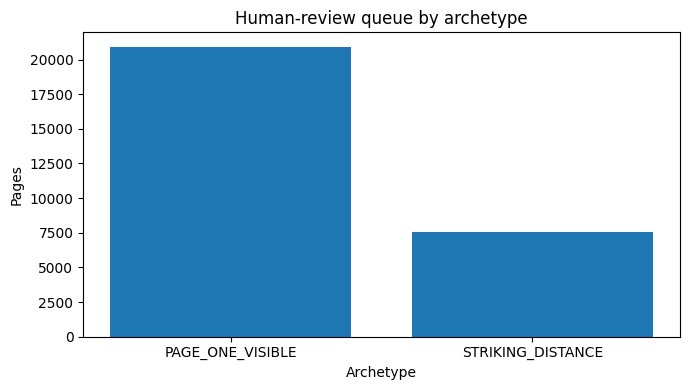

Queue CSV: work/outputs/content_action_queue.csv
Queue rows: 28,474
Metrics JSON: work/outputs/action_playbook_metrics.json
Figure: work/figures/action_queue_archetypes.png

Metrics receipt:
{
  "development_period": "2026-03-01 to 2026-03-21",
  "queue_rows": 28474,
  "page_one_visible_pages": 20916,
  "striking_distance_pages": 7558,
  "priority_definition": "pre-decision search impressions",
  "grouped_validation_precision_at_50_pct": 28.0,
  "grouped_validation_base_rate_pct": 29.9,
  "grouped_validation_client_overlap": 0,
  "automation_status": "human_review_only"
}


In [5]:
# Export reproducible artifacts for the research paper.

from pathlib import Path
import json
import matplotlib.pyplot as plt


OUTPUT_DIR = Path("work/outputs")
FIGURE_DIR = Path("work/figures")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# 1. Full ranked queue: regenerated locally and intentionally excluded from Git.
queue_path = OUTPUT_DIR / "content_action_queue.csv"
action_queue.to_csv(queue_path, index=False)


# 2. Small committed receipt for numbers that may be cited in the paper.
archetype_counts = action_queue["archetype"].value_counts()

metrics_receipt = {
    "development_period": "2026-03-01 to 2026-03-21",
    "queue_rows": int(len(action_queue)),
    "page_one_visible_pages": int(
        archetype_counts.get("PAGE_ONE_VISIBLE", 0)
    ),
    "striking_distance_pages": int(
        archetype_counts.get("STRIKING_DISTANCE", 0)
    ),
    "priority_definition": "pre-decision search impressions",
    "grouped_validation_precision_at_50_pct": 28.0,
    "grouped_validation_base_rate_pct": 29.9,
    "grouped_validation_client_overlap": 0,
    "automation_status": "human_review_only",
}

metrics_path = OUTPUT_DIR / "action_playbook_metrics.json"

with metrics_path.open("w", encoding="utf-8") as file:
    json.dump(metrics_receipt, file, indent=2)


# 3. Aggregate figure that can be reused in the research paper.
archetype_plot = (
    action_queue["archetype"]
    .value_counts()
    .rename_axis("archetype")
    .reset_index(name="pages")
)

fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    archetype_plot["archetype"],
    archetype_plot["pages"],
)

ax.set_title("Human-review queue by archetype")
ax.set_xlabel("Archetype")
ax.set_ylabel("Pages")

fig.tight_layout()

figure_path = FIGURE_DIR / "action_queue_archetypes.png"
fig.savefig(figure_path, dpi=150, bbox_inches="tight")

plt.show()


# Print receipts so the exported artifacts can be checked during Run All.
print(f"Queue CSV: {queue_path}")
print(f"Queue rows: {len(action_queue):,}")
print(f"Metrics JSON: {metrics_path}")
print(f"Figure: {figure_path}")
print()
print("Metrics receipt:")
print(json.dumps(metrics_receipt, indent=2))


## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.